In [1]:
print("Welcome to Supermarket Sales Analysis Project")


Welcome to Supermarket Sales Analysis Project


In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
import pandas as pd

df = pd.read_csv("supermarket_sales.csv")

print(df.head())

FileNotFoundError: [Errno 2] No such file or directory: 'supermarket_sales.csv'

EmptyDataError: No columns to parse from file

In [5]:
import os

print(os.path.getsize("supermarket_sales.csv"), "bytes")

0 bytes


In [6]:
import os

for file in os.listdir():
    if file.endswith(".csv"):
        print(file, os.path.getsize(file), "bytes")

annex1.csv 16597 bytes
annex2.csv 51794172 bytes
annex3.csv 1843940 bytes
annex4.csv 10805 bytes
supermarket_sales.csv 0 bytes


In [7]:
import os

for file in os.listdir():
    if file.endswith(".csv"):
        print(file, os.path.getsize(file), "bytes")

annex1.csv 16597 bytes
annex2.csv 51794172 bytes
annex3.csv 1843940 bytes
annex4.csv 10805 bytes
supermarket_sales.csv 0 bytes


In [8]:
import pandas as pd

files = ["annex1.csv", "annex2.csv", "annex3.csv", "annex4.csv"]

for file in files:
    print("\nFile:", file)
    data = pd.read_csv(file, nrows=5)
    print("Columns:", data.columns.tolist())
    print(data.head(2))


File: annex1.csv
Columns: ['Item Code', 'Item Name', 'Category Code', 'Category Name']
         Item Code          Item Name  Category Code           Category Name
0  102900005115168   Niushou Shengcai     1011010101  Flower/Leaf Vegetables
1  102900005115199  Sichuan Red Cedar     1011010101  Flower/Leaf Vegetables

File: annex2.csv
Columns: ['Date', 'Time', 'Item Code', 'Quantity Sold (kilo)', 'Unit Selling Price (RMB/kg)', 'Sale or Return', 'Discount (Yes/No)']
         Date          Time        Item Code  Quantity Sold (kilo)  \
0  2020-07-01  09:15:07.924  102900005117056                 0.396   
1  2020-07-01  09:17:27.295  102900005115960                 0.849   

   Unit Selling Price (RMB/kg) Sale or Return Discount (Yes/No)  
0                          7.6           sale                No  
1                          3.2           sale                No  

File: annex3.csv
Columns: ['Date', 'Item Code', 'Wholesale Price (RMB/kg)']
         Date        Item Code  Wholesale Pr

In [9]:
import pandas as pd

# Load all datasets
items = pd.read_csv("annex1.csv", dtype={"Item Code": str})
sales = pd.read_csv("annex2.csv", dtype={"Item Code": str})
wholesale = pd.read_csv("annex3.csv", dtype={"Item Code": str})
loss = pd.read_csv("annex4.csv", dtype={"Item Code": str})

# Convert dates
sales["Date"] = pd.to_datetime(sales["Date"])
wholesale["Date"] = pd.to_datetime(wholesale["Date"])

# Merge datasets
df = sales.merge(items, on="Item Code", how="left")

df = df.merge(
    wholesale,
    on=["Date", "Item Code"],
    how="left"
)

df = df.merge(
    loss[["Item Code", "Loss Rate (%)"]],
    on="Item Code",
    how="left"
)

print("Dataset merged successfully!")
print("Shape:", df.shape)

df.head()

Dataset merged successfully!
Shape: (878503, 12)


,Date,Time,Item Code,Quantity Sold (kilo),Unit Selling Price (RMB/kg),Sale or Return,Discount (Yes/No),Item Name,Category Code,Category Name,Wholesale Price (RMB/kg),Loss Rate (%)
0,2020-07-01,09:15:07.924,102900005117056,0.396,7.6,sale,No,Paopaojiao (Jingpin),1011010504,Capsicum,4.32,7.08
1,2020-07-01,09:17:27.295,102900005115960,0.849,3.2,sale,No,Chinese Cabbage,1011010101,Flower/Leaf Vegetables,2.10,22.27
2,2020-07-01,09:17:33.905,102900005117056,0.409,7.6,sale,No,Paopaojiao (Jingpin),1011010504,Capsicum,4.32,7.08
3,2020-07-01,09:19:45.450,102900005115823,0.421,10.0,sale,No,Shanghaiqing,1011010101,Flower/Leaf Vegetables,7.03,14.43
4,2020-07-01,09:20:23.686,102900005115908,0.539,8.0,sale,No,Caixin,1011010101,Flower/Leaf Vegetables,4.60,13.70


In [10]:
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 878503 entries, 0 to 878502
Data columns (total 12 columns):
 #   Column                       Non-Null Count   Dtype         
---  ------                       --------------   -----         
 0   Date                         878503 non-null  datetime64[us]
 1   Time                         878503 non-null  str           
 2   Item Code                    878503 non-null  str           
 3   Quantity Sold (kilo)         878503 non-null  float64       
 4   Unit Selling Price (RMB/kg)  878503 non-null  float64       
 5   Sale or Return               878503 non-null  str           
 6   Discount (Yes/No)            878503 non-null  str           
 7   Item Name                    878503 non-null  str           
 8   Category Code                878503 non-null  int64         
 9   Category Name                878503 non-null  str           
 10  Wholesale Price (RMB/kg)     878503 non-null  float64       
 11  Loss Rate (%)                878503 n

In [11]:
# Check duplicate records
duplicates = df.duplicated().sum()

print("Total Duplicate Records:", duplicates)

# Remove duplicates if any
df = df.drop_duplicates()

print("Dataset Shape After Cleaning:", df.shape)

Total Duplicate Records: 0
Dataset Shape After Cleaning: (878503, 12)


In [12]:
# Calculate revenue
df["Revenue (RMB)"] = (
    df["Quantity Sold (kilo)"] *
    df["Unit Selling Price (RMB/kg)"]
)

print("Total Revenue:", df["Revenue (RMB)"].sum())
print("Total Quantity Sold:", df["Quantity Sold (kilo)"].sum())

Total Revenue: 3369766.4768000003
Total Quantity Sold: 470975.91800000006


In [13]:
# Calculate revenue
df["Revenue (RMB)"] = (
    df["Quantity Sold (kilo)"] *
    df["Unit Selling Price (RMB/kg)"]
)

print("Total Revenue:", df["Revenue (RMB)"].sum())
print("Total Quantity Sold:", df["Quantity Sold (kilo)"].sum())

Total Revenue: 3369766.4768000003
Total Quantity Sold: 470975.91800000006


In [14]:
# Calculate revenue
df["Revenue (RMB)"] = (
    df["Quantity Sold (kilo)"] *
    df["Unit Selling Price (RMB/kg)"]
)

print("Total Revenue:", df["Revenue (RMB)"].sum())

print("Total Quantity Sold:",
      df["Quantity Sold (kilo)"].sum())

Total Revenue: 3369766.4768000003
Total Quantity Sold: 470975.91800000006


In [15]:
vegetable_sales = df.groupby("Item Name")["Quantity Sold (kilo)"].sum()

top_10 = vegetable_sales.sort_values(ascending=False).head(10)

print(top_10)

Item Name
Wuhu Green Pepper (1)    28164.331
Broccoli                 27537.899
Net Lotus Root (1)       27149.440
Chinese Cabbage          20894.521
Yunnan Shengcai          15910.461
Needle Mushroom (Box)    15596.000
Yunnan Lettuce (Bag)     14325.000
Eggplant (2)             13602.001
Xixia Mushroom (1)       11920.227
Millet Pepper (Bag)      10833.000
Name: Quantity Sold (kilo), dtype: float64


In [16]:
# Consider only actual sales, excluding returns
sales_data = df[
    df["Sale or Return"].str.lower() == "sale"
]

# Calculate vegetable-wise quantity
vegetable_sales = sales_data.groupby("Item Name")[
    "Quantity Sold (kilo)"
].sum()

# Find top 10 vegetables
top_10 = vegetable_sales.sort_values(
    ascending=False
).head(10)

print(top_10)

Item Name
Wuhu Green Pepper (1)    28181.741
Broccoli                 27556.616
Net Lotus Root (1)       27166.459
Chinese Cabbage          20905.257
Yunnan Shengcai          15915.422
Needle Mushroom (Box)    15602.000
Yunnan Lettuce (Bag)     14335.000
Eggplant (2)             13608.976
Xixia Mushroom (1)       11929.100
Millet Pepper (Bag)      10847.000
Name: Quantity Sold (kilo), dtype: float64


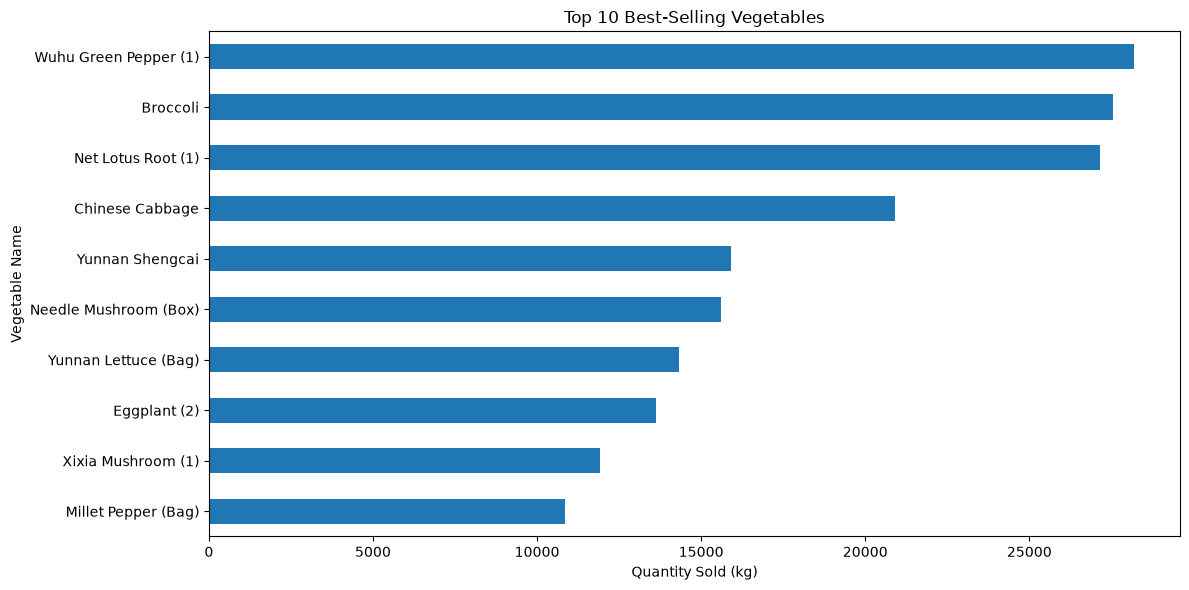

In [17]:
plt.figure(figsize=(12, 6))

top_10.sort_values().plot(
    kind="barh",
    title="Top 10 Best-Selling Vegetables"
)

plt.xlabel("Quantity Sold (kg)")
plt.ylabel("Vegetable Name")
plt.tight_layout()
plt.show()

In [18]:
category_sales = sales_data.groupby("Category Name")[
    "Quantity Sold (kilo)"
].sum().sort_values(ascending=False)

print(category_sales)

Category Name
Flower/Leaf Vegetables         198659.553
Capsicum                        91645.112
Edible Mushroom                 76131.726
Cabbage                         41789.777
Aquatic Tuberous Vegetables     40607.552
Solanum                         22442.119
Name: Quantity Sold (kilo), dtype: float64


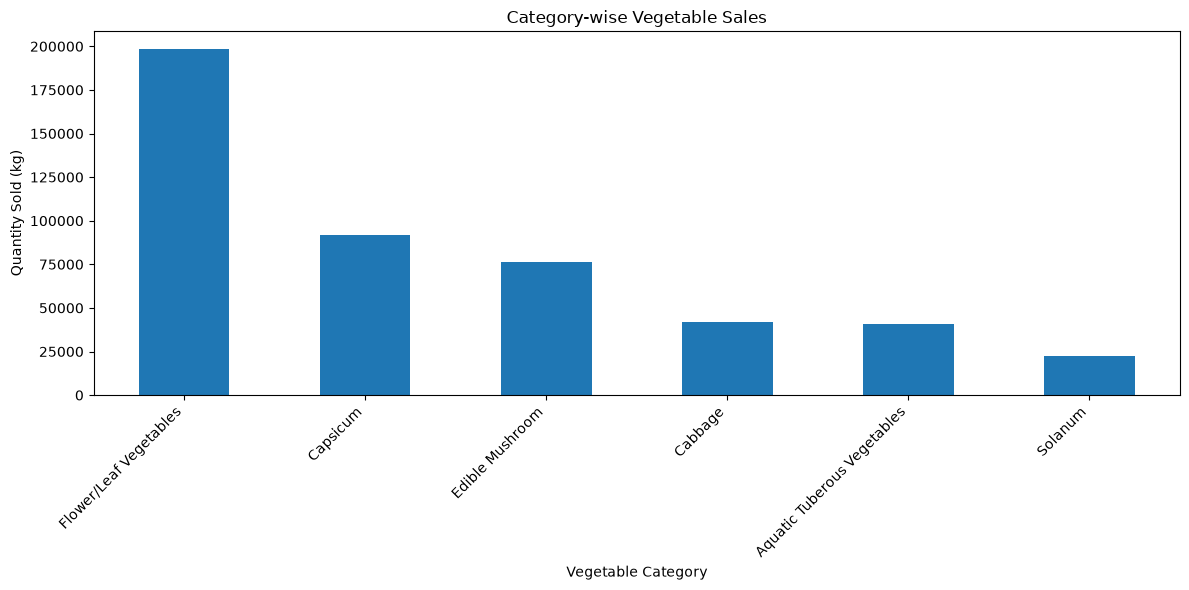

In [19]:
plt.figure(figsize=(12, 6))

category_sales.plot(kind="bar")

plt.title("Category-wise Vegetable Sales")
plt.xlabel("Vegetable Category")
plt.ylabel("Quantity Sold (kg)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [20]:
daily_sales = sales_data.groupby("Date")[
    "Quantity Sold (kilo)"
].sum()

print(daily_sales.head(10))

Date
2020-07-01    404.782
2020-07-02    393.678
2020-07-03    386.018
2020-07-04    483.299
2020-07-05    516.917
2020-07-06    371.537
2020-07-07    350.803
2020-07-08    364.126
2020-07-09    353.294
2020-07-10    389.427
Name: Quantity Sold (kilo), dtype: float64


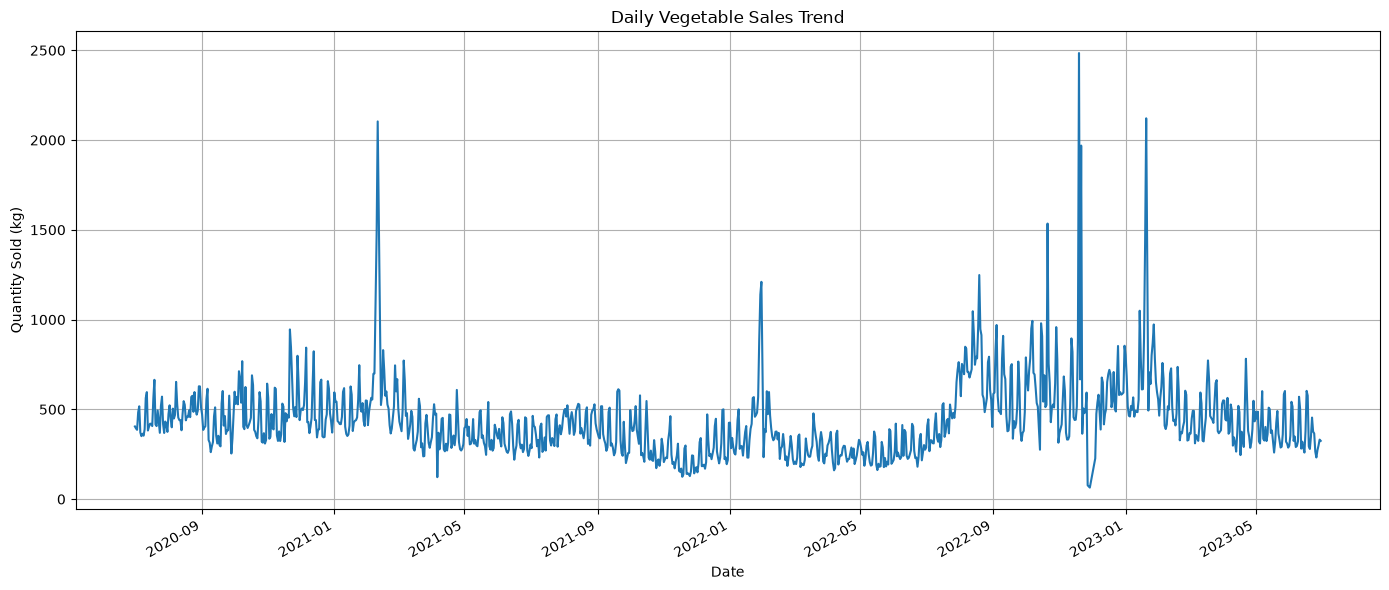

In [21]:
plt.figure(figsize=(14, 6))

daily_sales.plot(kind="line")

plt.title("Daily Vegetable Sales Trend")
plt.xlabel("Date")
plt.ylabel("Quantity Sold (kg)")
plt.grid(True)

plt.tight_layout()
plt.show()

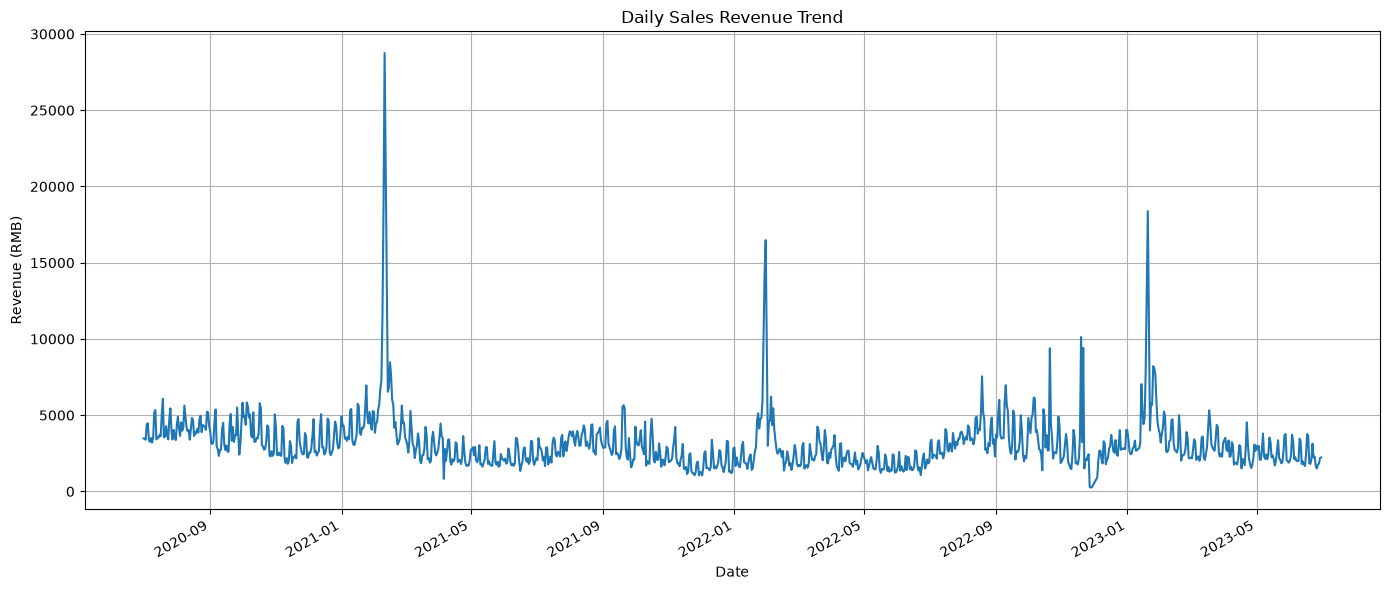

In [22]:
# Calculate daily revenue
daily_revenue = sales_data.groupby("Date")["Revenue (RMB)"].sum()

plt.figure(figsize=(14, 6))
daily_revenue.plot(kind="line")

plt.title("Daily Sales Revenue Trend")
plt.xlabel("Date")
plt.ylabel("Revenue (RMB)")
plt.grid(True)
plt.tight_layout()
plt.show()

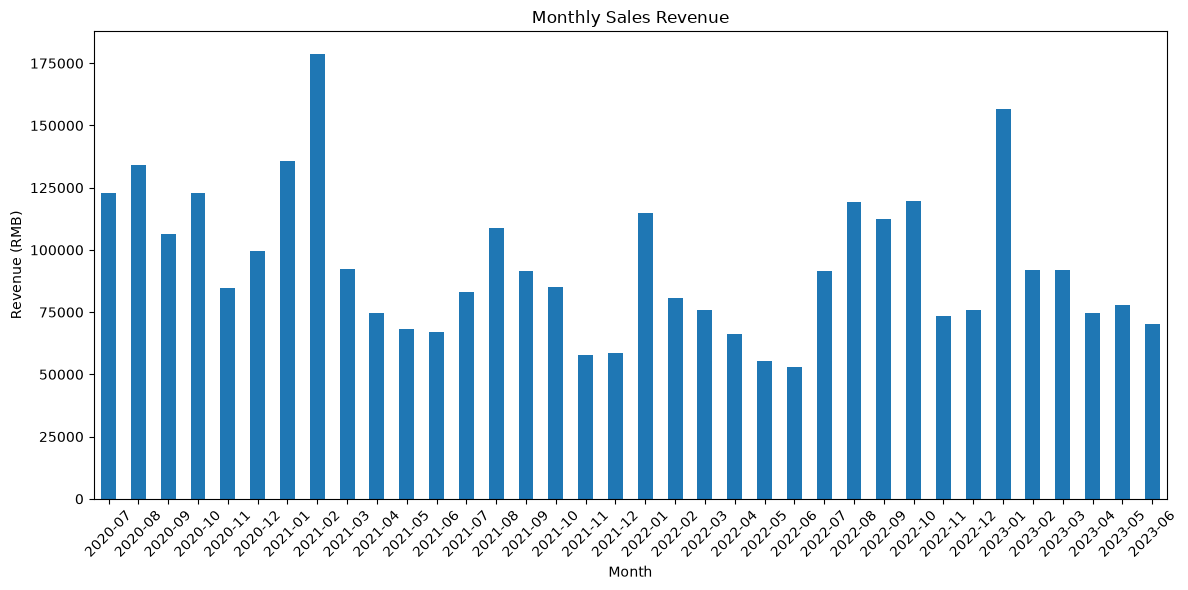

In [23]:
monthly_revenue = sales_data.groupby(
    sales_data["Date"].dt.to_period("M")
)["Revenue (RMB)"].sum()

plt.figure(figsize=(12, 6))
monthly_revenue.plot(kind="bar")

plt.title("Monthly Sales Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (RMB)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

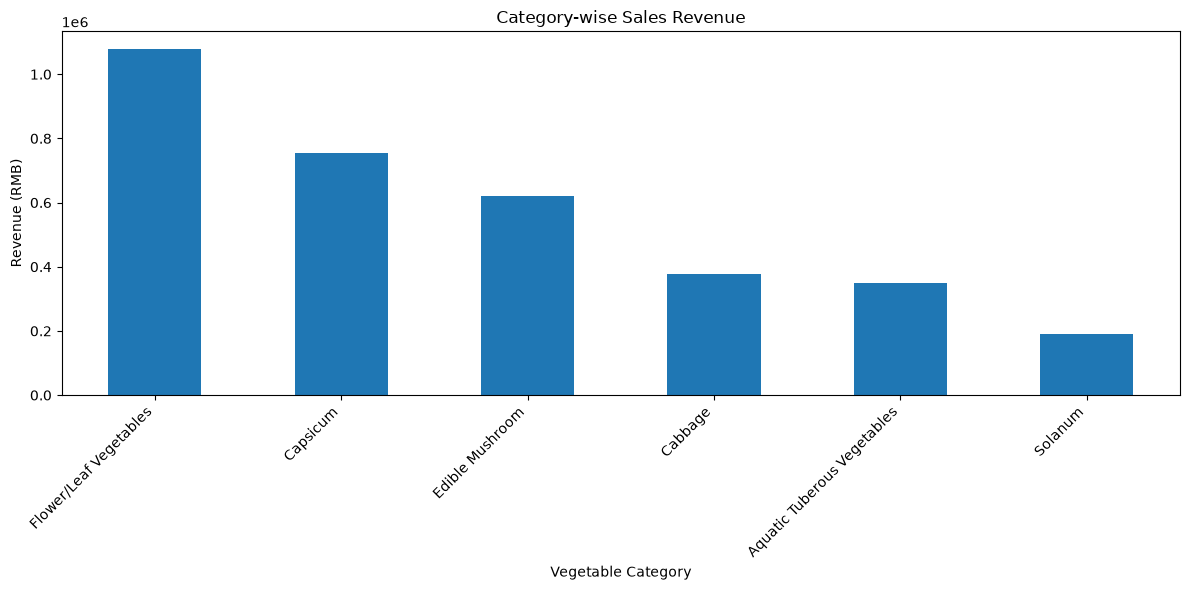

In [24]:
category_revenue = sales_data.groupby("Category Name")[
    "Revenue (RMB)"
].sum().sort_values(ascending=False)

plt.figure(figsize=(12, 6))
category_revenue.plot(kind="bar", figsize=(12, 6))

plt.title("Category-wise Sales Revenue")
plt.xlabel("Vegetable Category")
plt.ylabel("Revenue (RMB)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [25]:
discount_analysis = sales_data.groupby(
    "Discount (Yes/No)"
).agg(
    Total_Quantity=("Quantity Sold (kilo)", "sum"),
    Total_Revenue=("Revenue (RMB)", "sum"),
    Transactions=("Item Code", "count")
)

print(discount_analysis)

                   Total_Quantity  Total_Revenue  Transactions
Discount (Yes/No)                                             
No                     439522.732   3.210892e+06        830680
Yes                     31753.107   1.611313e+05         47362


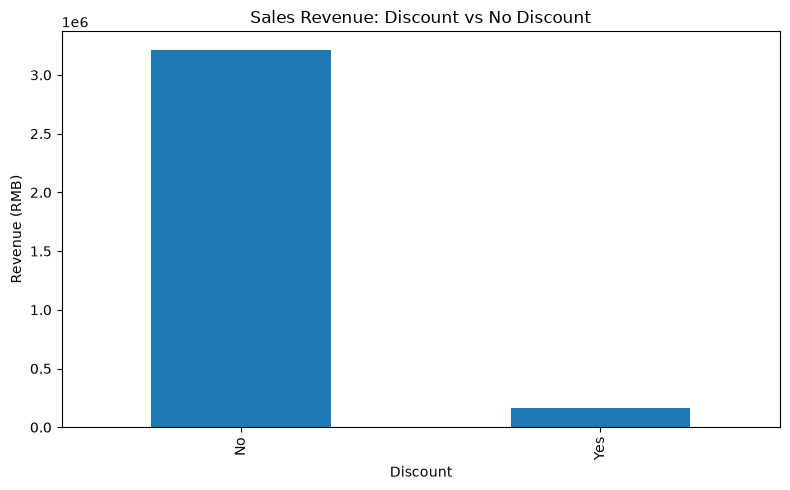

In [26]:
discount_analysis["Total_Revenue"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Sales Revenue: Discount vs No Discount"
)

plt.xlabel("Discount")
plt.ylabel("Revenue (RMB)")
plt.tight_layout()
plt.show()

In [27]:
loss_analysis = df.groupby("Item Name")[
    "Loss Rate (%)"
].mean().sort_values(ascending=False)

top_loss = loss_analysis.head(10)

print(top_loss)

Item Name
High Melon (1)                    29.250000
Chuncai                           29.030000
Dongmenkou Xiaobaicai             27.840000
Foreign Garland Chrysanthemum     26.160000
Purple Cabbage (1)                25.530000
Honghu Lotus Root                 24.050000
Kuaicai                           20.380000
The Steak Mushrooms (Box)         19.800000
Purple Beicai                     19.580000
Chinese Cabbage                   19.226361
Name: Loss Rate (%), dtype: float64


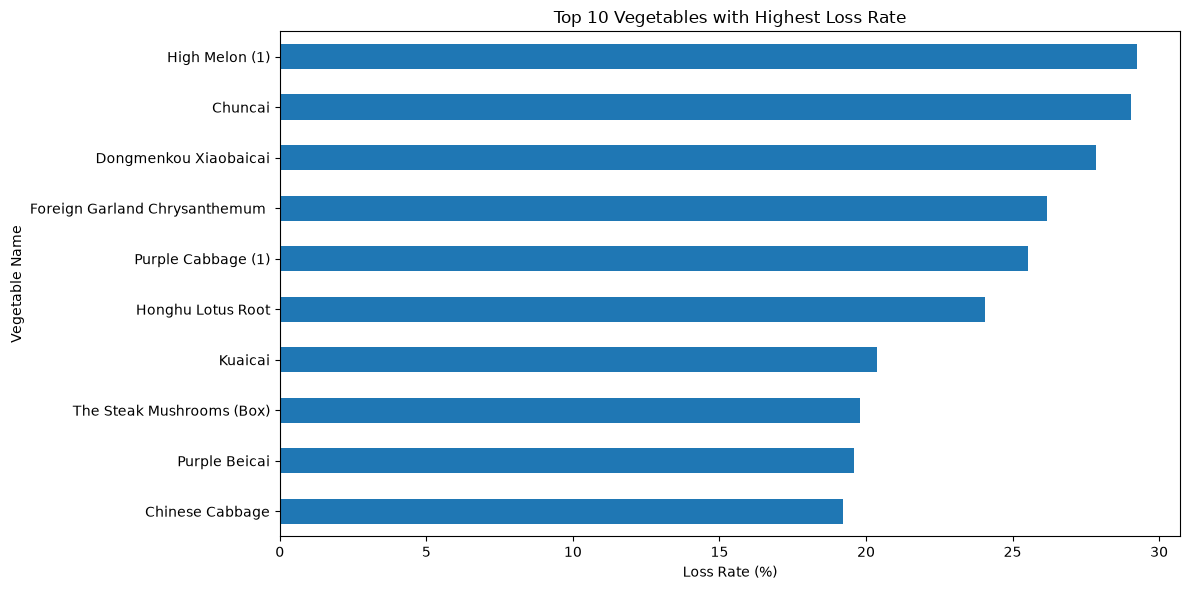

In [28]:
plt.figure(figsize=(12, 6))

top_loss.sort_values().plot(kind="barh")

plt.title("Top 10 Vegetables with Highest Loss Rate")
plt.xlabel("Loss Rate (%)")
plt.ylabel("Vegetable Name")

plt.tight_layout()
plt.show()

In [29]:
# Calculate estimated cost after considering vegetable loss
df["Adjusted Cost (RMB/kg)"] = (
    df["Wholesale Price (RMB/kg)"] /
    (1 - df["Loss Rate (%)"] / 100)
)

# Calculate estimated profit per kg
df["Profit per kg (RMB)"] = (
    df["Unit Selling Price (RMB/kg)"] -
    df["Adjusted Cost (RMB/kg)"]
)

# Calculate estimated profit
df["Estimated Profit (RMB)"] = (
    df["Quantity Sold (kilo)"] *
    df["Profit per kg (RMB)"]
)

print("Estimated Total Profit:",
      df["Estimated Profit (RMB)"].sum())

Estimated Total Profit: 1003953.1763958801


In [31]:
profit_analysis = df[
    df["Sale or Return"].str.lower() == "sale"
].groupby("Item Name")["Estimated Profit (RMB)"].sum()

top_profit = profit_analysis.sort_values(
    ascending=False
).head(10)

print(top_profit)

Item Name
Broccoli                 71842.164040
Net Lotus Root (1)       53614.713774
Wuhu Green Pepper (1)    52732.600366
Xixia Mushroom (1)       49098.143030
Yunnan Shengcai          35631.752173
Eggplant (2)             35132.369528
Millet Pepper (Bag)      24467.774539
Luosi Pepper             22093.628426
Yunnan Lettuces          21615.366021
Yunnan Lettuce (Bag)     21578.311306
Name: Estimated Profit (RMB), dtype: float64


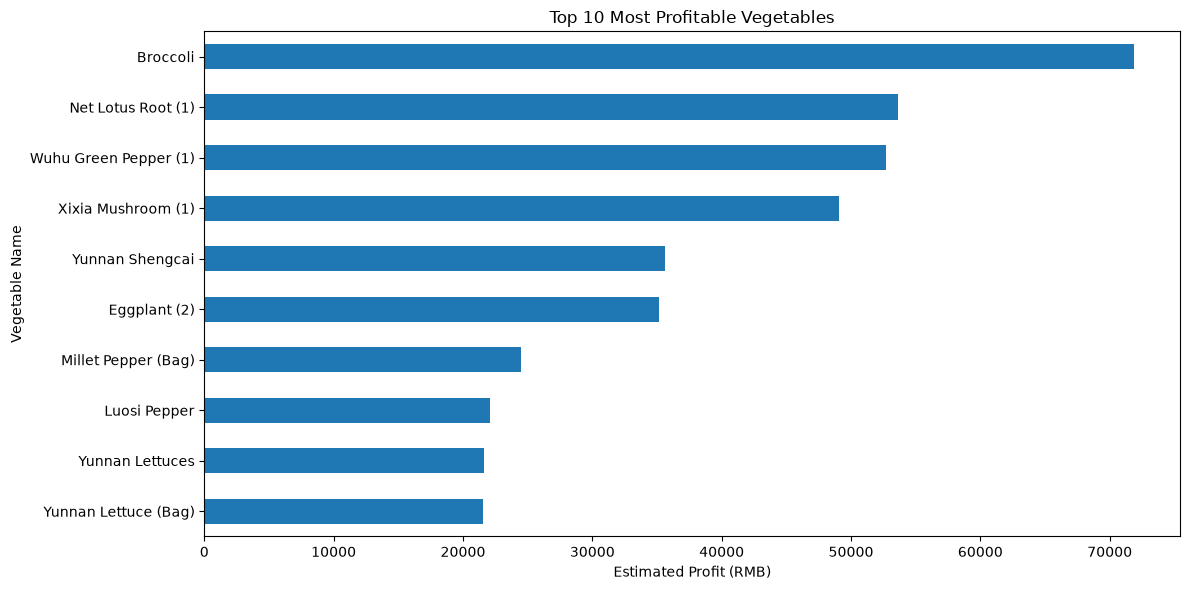

In [32]:
plt.figure(figsize=(12, 6))

top_profit.sort_values().plot(kind="barh")

plt.title("Top 10 Most Profitable Vegetables")
plt.xlabel("Estimated Profit (RMB)")
plt.ylabel("Vegetable Name")

plt.tight_layout()
plt.show()

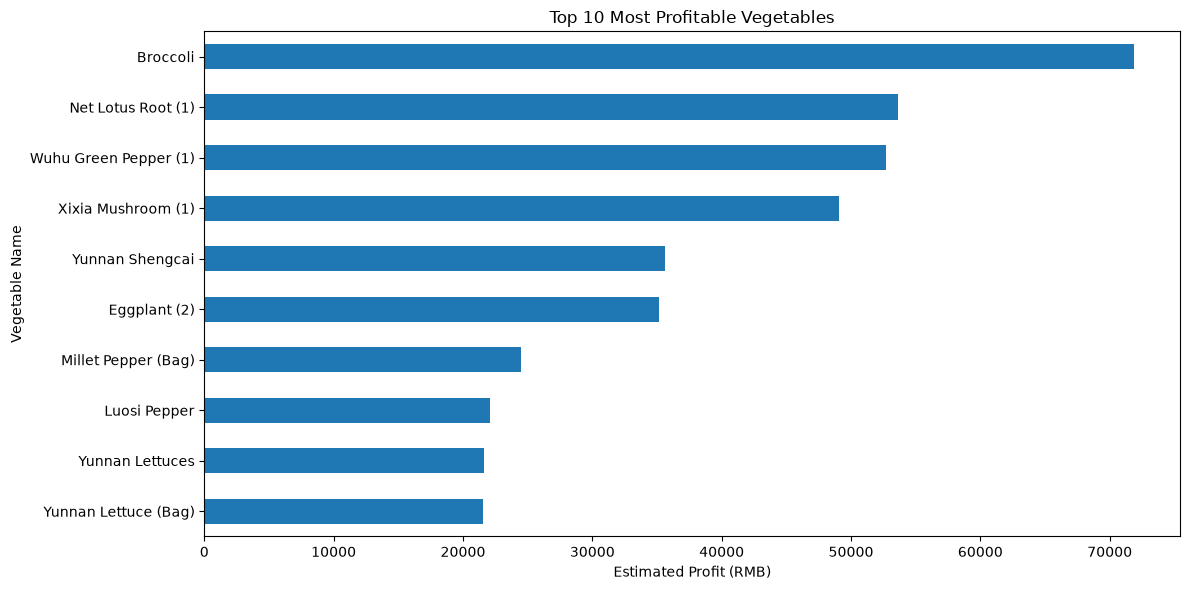

In [33]:
plt.figure(figsize=(12, 6))

top_profit.sort_values().plot(kind="barh")

plt.title("Top 10 Most Profitable Vegetables")
plt.xlabel("Estimated Profit (RMB)")
plt.ylabel("Vegetable Name")

plt.tight_layout()
plt.show()

Item Name
Wuhu Green Pepper (1)    28181.741
Broccoli                 27556.616
Net Lotus Root (1)       27166.459
Chinese Cabbage          20905.257
Yunnan Shengcai          15915.422
Needle Mushroom (Box)    15602.000
Yunnan Lettuce (Bag)     14335.000
Eggplant (2)             13608.976
Xixia Mushroom (1)       11929.100
Millet Pepper (Bag)      10847.000
Name: Quantity Sold (kilo), dtype: float64


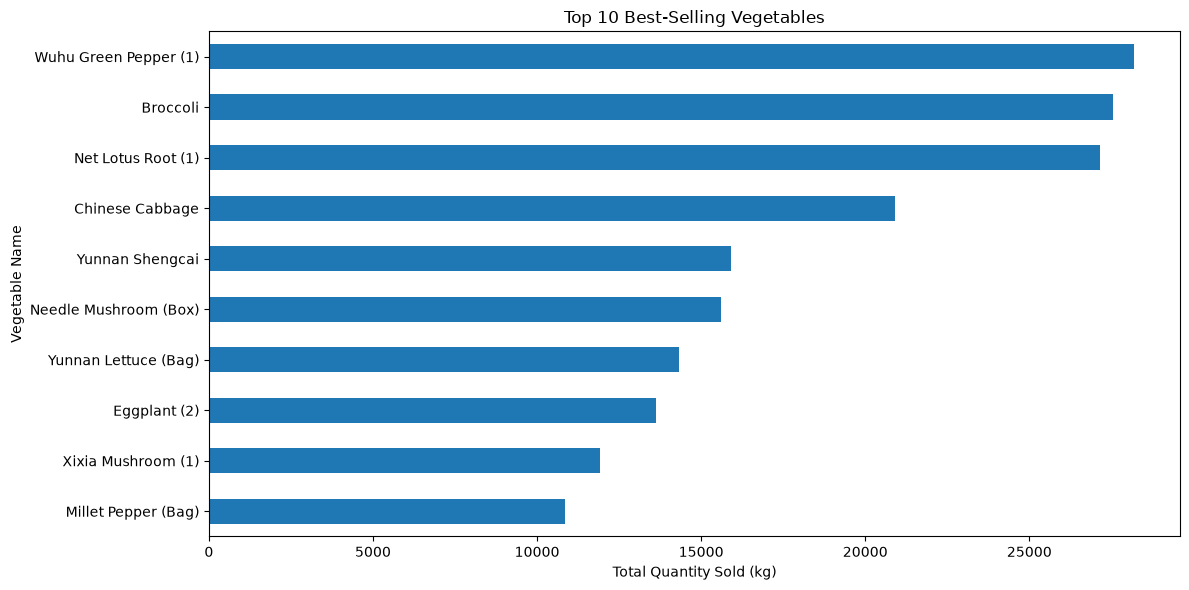

In [35]:
import pandas as pd
import matplotlib.pyplot as plt

# Select only sales records
sales = df[df['Sale or Return'].str.lower() == 'sale']

# Calculate total quantity sold for each vegetable
top_vegetables = sales.groupby('Item Name')['Quantity Sold (kilo)'].sum()

# Get top 10 vegetables
top_10 = top_vegetables.nlargest(10)

# Display results
print(top_10)

# Create graph
plt.figure(figsize=(12, 6))
top_10.sort_values().plot(kind='barh')

plt.title('Top 10 Best-Selling Vegetables')
plt.xlabel('Total Quantity Sold (kg)')
plt.ylabel('Vegetable Name')
plt.tight_layout()
plt.show()

In [37]:
print(df.columns.tolist())

['Date', 'Time', 'Item Code', 'Quantity Sold (kilo)', 'Unit Selling Price (RMB/kg)', 'Sale or Return', 'Discount (Yes/No)', 'Item Name', 'Category Code', 'Category Name', 'Wholesale Price (RMB/kg)', 'Loss Rate (%)', 'Revenue (RMB)', 'Adjusted Cost (RMB/kg)', 'Profit per kg (RMB)', 'Estimated Profit (RMB)']


Item Name
Broccoli                 270067.2656
Net Lotus Root (1)       211769.9397
Xixia Mushroom (1)       211356.7198
Wuhu Green Pepper (1)    205219.9385
Yunnan Shengcai          129797.0675
Eggplant (2)             117797.5297
Paopaojiao (Jingpin)      95610.6849
Luosi Pepper              82031.9321
Yunnan Lettuces           70692.2511
Chinese Cabbage           65729.6492
Name: Revenue (RMB), dtype: float64


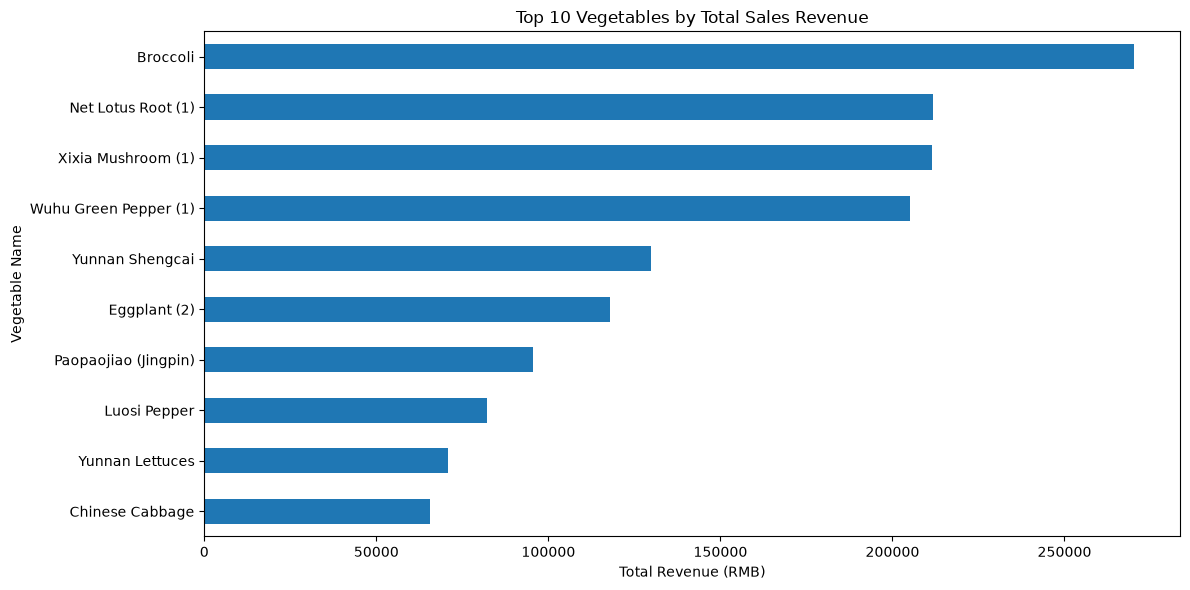

In [38]:
# Calculate total revenue for each vegetable
total_sales = sales.groupby('Item Name')['Revenue (RMB)'].sum()

# Find top 10 vegetables
top_sales = total_sales.nlargest(10)

# Display results
print(top_sales)

# Create graph
plt.figure(figsize=(12, 6))
top_sales.sort_values().plot(kind='barh')

plt.title('Top 10 Vegetables by Total Sales Revenue')
plt.xlabel('Total Revenue (RMB)')
plt.ylabel('Vegetable Name')
plt.tight_layout()
plt.show()

Month
1     407232.7986
2     351365.0341
3     259930.5406
4     215650.2934
5     201572.7913
6     189964.7770
7     297596.2893
8     361704.5769
9     310176.8893
10    327275.2720
11    215649.4785
12    233904.6013
Name: Revenue (RMB), dtype: float64


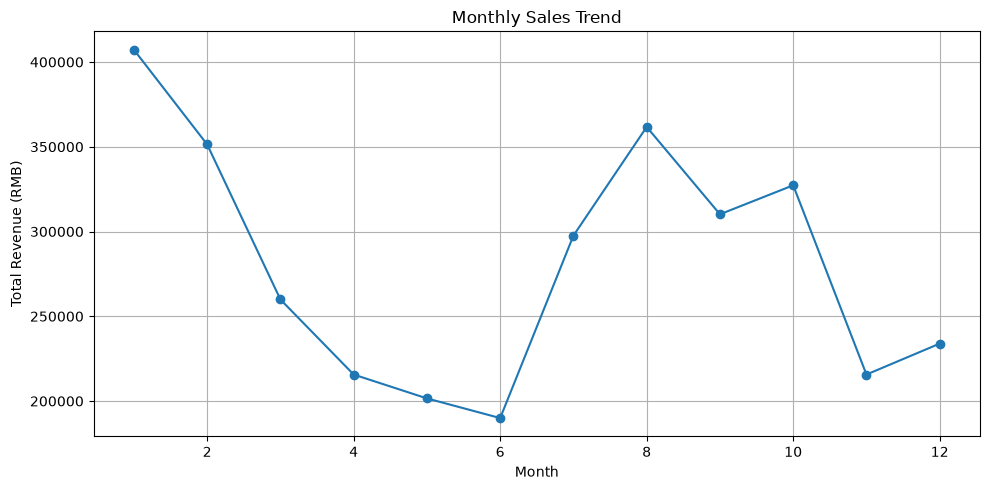

In [39]:
# Convert Date into datetime format
sales['Date'] = pd.to_datetime(sales['Date'])

# Extract month
sales['Month'] = sales['Date'].dt.month

# Calculate monthly revenue
monthly_sales = sales.groupby('Month')['Revenue (RMB)'].sum()

print(monthly_sales)

# Plot graph
plt.figure(figsize=(10,5))
monthly_sales.plot(kind='line', marker='o')

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Revenue (RMB)')
plt.grid(True)
plt.tight_layout()
plt.show()

Category Name
Flower/Leaf Vegetables         336679.632852
Capsicum                       238458.630856
Edible Mushroom                184641.304801
Cabbage                        102096.699156
Aquatic Tuberous Vegetables     81757.366943
Solanum                         61101.256733
Name: Estimated Profit (RMB), dtype: float64


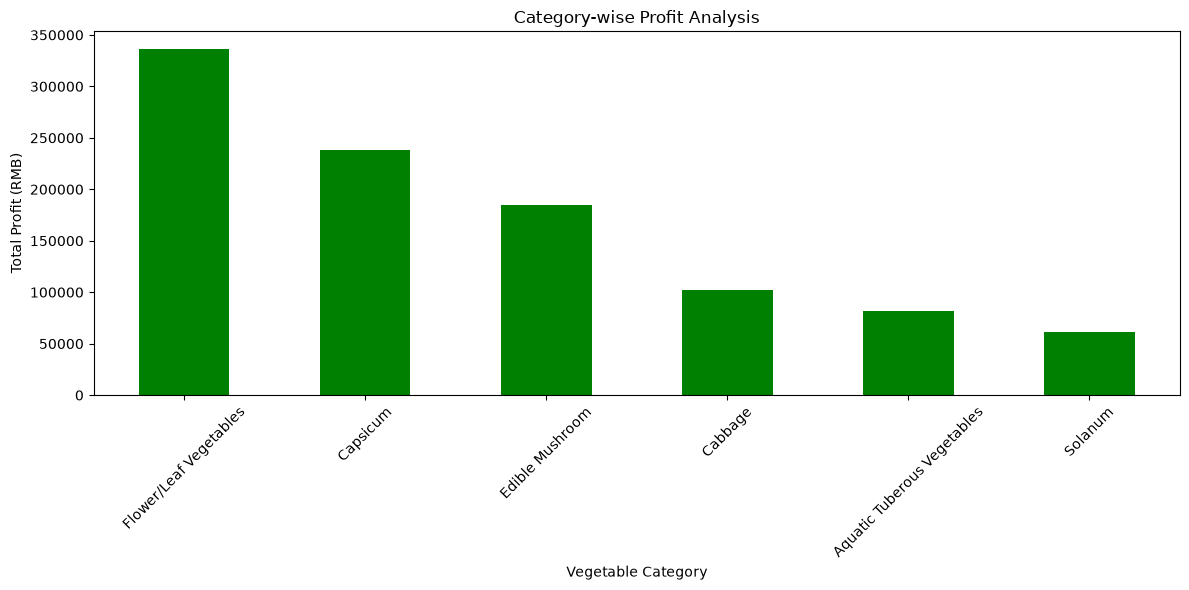

In [40]:
# Calculate profit category-wise
category_profit = sales.groupby('Category Name')['Estimated Profit (RMB)'].sum()

# Sort profit in descending order
category_profit = category_profit.sort_values(ascending=False)

print(category_profit)

# Plot graph
plt.figure(figsize=(12,6))
category_profit.plot(kind='bar', color='green')

plt.title('Category-wise Profit Analysis')
plt.xlabel('Vegetable Category')
plt.ylabel('Total Profit (RMB)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [43]:
sales.to_csv("cleaned_supermarket_sales.csv", index=False)

print("Dataset exported successfully!")

Dataset exported successfully!


In [45]:
import os
print(os.getcwd())

C:\Users\SHAIKH TAHURA\New folder (3)\Untitled Folder


In [46]:
import os

print(os.getcwd())
print(os.path.exists("cleaned_supermarket_sales.csv"))

C:\Users\SHAIKH TAHURA\New folder (3)\Untitled Folder
True


In [49]:
import os

print(os.getcwd())

C:\Users\SHAIKH TAHURA\New folder (3)\Untitled Folder


In [50]:
sales.to_csv("cleaned_supermarket_sales.csv", index=False)

print("Saved successfully!")

Saved successfully!


In [52]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

In [53]:
print("Dataset loaded:", 'sales' in globals())

Dataset loaded: True


In [54]:
print(sales.columns.tolist())

['Date', 'Time', 'Item Code', 'Quantity Sold (kilo)', 'Unit Selling Price (RMB/kg)', 'Sale or Return', 'Discount (Yes/No)', 'Item Name', 'Category Code', 'Category Name', 'Wholesale Price (RMB/kg)', 'Loss Rate (%)', 'Revenue (RMB)', 'Adjusted Cost (RMB/kg)', 'Profit per kg (RMB)', 'Estimated Profit (RMB)', 'Month']


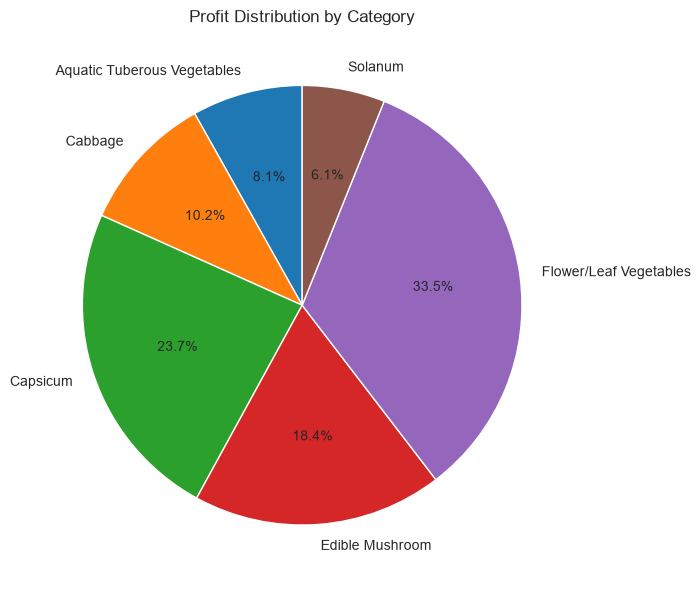

In [61]:
category_profit = sales.groupby('Category Name')['Estimated Profit (RMB)'].sum()

plt.figure(figsize=(10, 6))
category_profit.plot(kind='pie', autopct='%1.1f%%', startangle=90)

plt.title('Profit Distribution by Category')
plt.ylabel('')
plt.tight_layout()
plt.show()

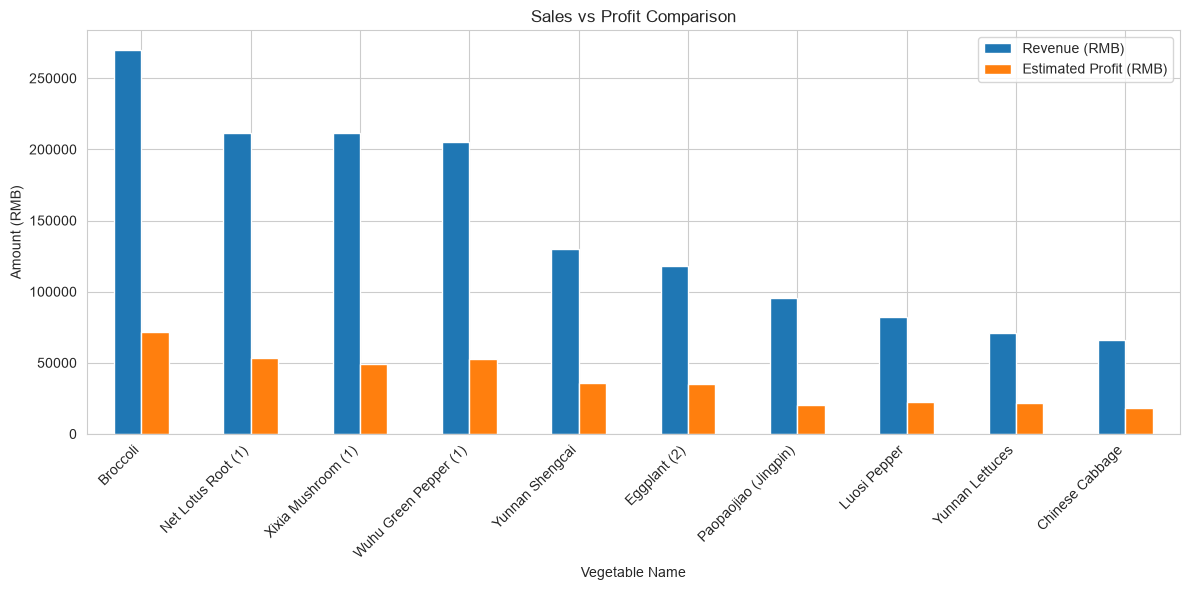

In [60]:
comparison = sales.groupby('Item Name')[['Revenue (RMB)', 'Estimated Profit (RMB)']].sum().sort_values(by='Revenue (RMB)', ascending=False).head(10)

comparison.plot(kind='bar', figsize=(12, 6))

plt.title('Sales vs Profit Comparison')
plt.xlabel('Vegetable Name')
plt.ylabel('Amount (RMB)')
plt.xticks(rotation=45, ha='right')
plt.legend()
plt.tight_layout()
plt.show()

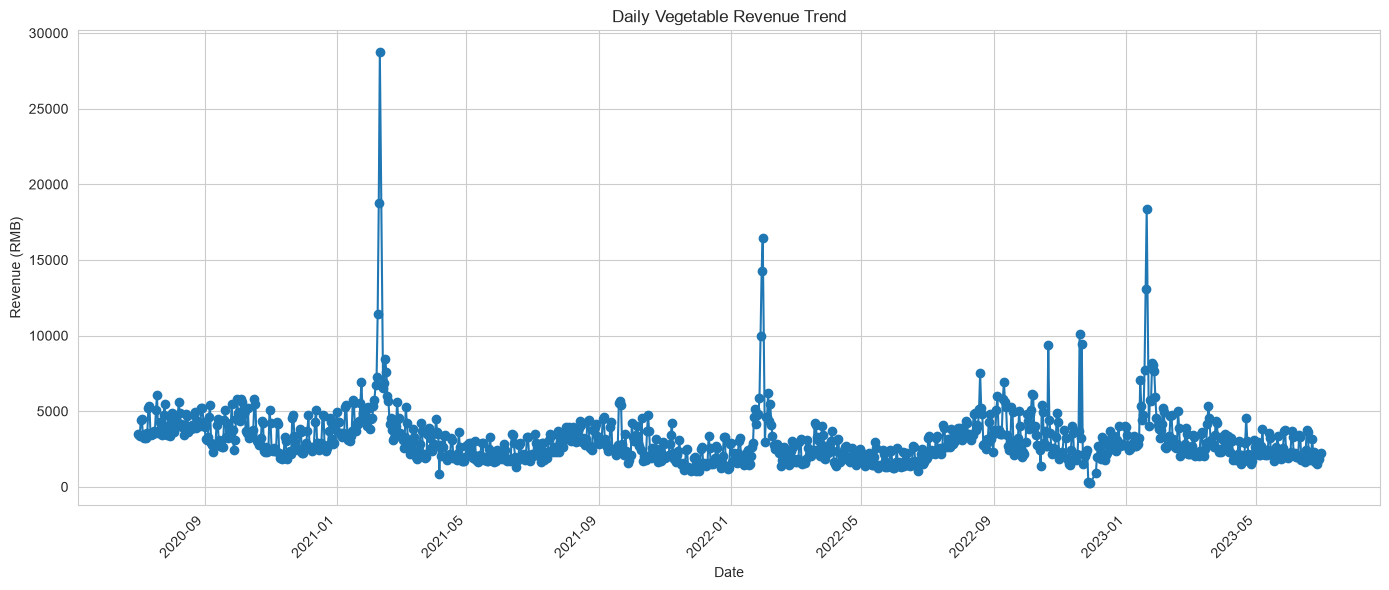

In [62]:
sales['Date'] = pd.to_datetime(sales['Date'])

daily_sales = sales.groupby('Date')['Revenue (RMB)'].sum()

plt.figure(figsize=(14, 6))
daily_sales.plot(kind='line', marker='o')

plt.title('Daily Vegetable Revenue Trend')
plt.xlabel('Date')
plt.ylabel('Revenue (RMB)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

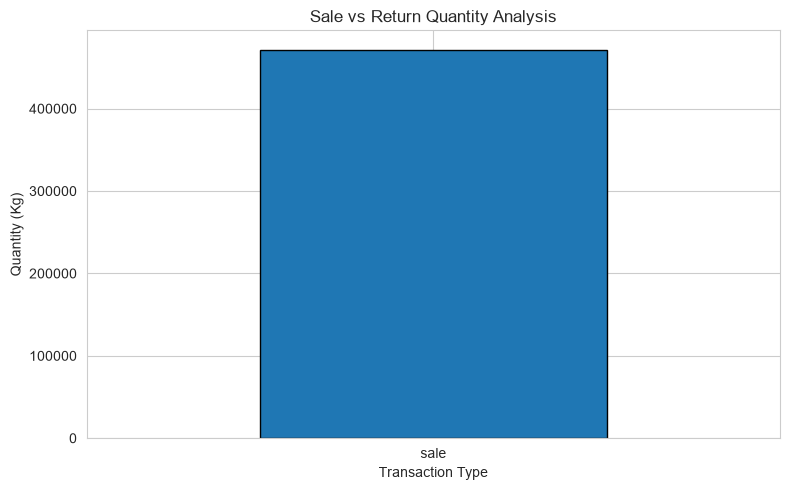

In [64]:
return_data = sales.groupby('Sale or Return')['Quantity Sold (kilo)'].sum()

plt.figure(figsize=(8, 5))
return_data.plot(kind='bar', edgecolor='black')

plt.title('Sale vs Return Quantity Analysis')
plt.xlabel('Transaction Type')
plt.ylabel('Quantity (Kg)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

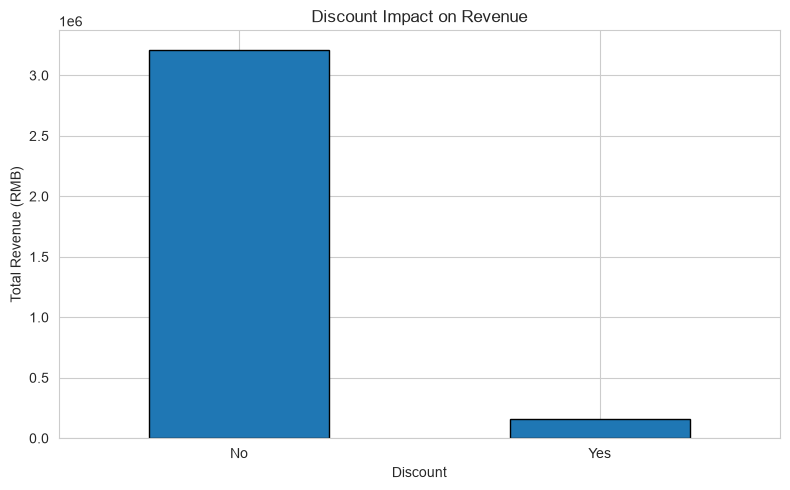

In [65]:
discount_sales = sales.groupby('Discount (Yes/No)')['Revenue (RMB)'].sum()

plt.figure(figsize=(8, 5))
discount_sales.plot(kind='bar', edgecolor='black')

plt.title('Discount Impact on Revenue')
plt.xlabel('Discount')
plt.ylabel('Total Revenue (RMB)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [66]:
import os

print(os.path.abspath("cleaned_supermarket_sales.csv"))

C:\Users\SHAIKH TAHURA\New folder (3)\Untitled Folder\cleaned_supermarket_sales.csv


In [68]:
import os

file_name = "cleaned_supermarket_sales.csv"

if os.path.exists(file_name):
    print("File exists!")
    print("File location:", os.path.abspath(file_name))
else:
    print("File not found!")

File exists!
File location: C:\Users\SHAIKH TAHURA\New folder (3)\Untitled Folder\cleaned_supermarket_sales.csv


In [69]:
import os
os.startfile(os.path.dirname(os.path.abspath("cleaned_supermarket_sales.csv")))